1. IMPORT AND SETUP LIBRARIES REQUIERED

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

print('Libraries loaded successfully.')

Libraries loaded successfully.


What the above cell does:
The cell above imports all python libraries needed to load, filter, group data and perform mathematical functions and make graphs.

2. LOADING THE RAW DATASET

In [3]:
df_rd = pd.read_csv('Global Youtube Statistics.csv', encoding='latin-1')
print(f'Raw shape: {df_rd.shape}')
df_rd.head(10)


Raw shape: (995, 28)


,rank,Youtuber,subscribers,video views,category,Title,uploads,Country,Abbreviation,channel_type,...,subscribers_for_last_30_days,created_year,created_month,created_date,Gross tertiary education enrollment (%),Population,Unemployment rate,Urban_population,Latitude,Longitude
0,1,T-Series,245000000,2.280000e+11,Music,T-Series,20082,India,IN,Music,...,2000000.0,2006.0,Mar,13.0,28.1,1.366418e+09,5.36,471031528.0,20.593684,78.962880
1,2,YouTube Movies,170000000,0.000000e+00,Film & Animation,youtubemovies,1,United States,US,Games,...,NaN,2006.0,Mar,5.0,88.2,3.282395e+08,14.70,270663028.0,37.090240,-95.712891
2,3,MrBeast,166000000,2.836884e+10,Entertainment,MrBeast,741,United States,US,Entertainment,...,8000000.0,2012.0,Feb,20.0,88.2,3.282395e+08,14.70,270663028.0,37.090240,-95.712891
3,4,Cocomelon - Nursery Rhymes,162000000,1.640000e+11,Education,Cocomelon - Nursery Rhymes,966,United States,US,Education,...,1000000.0,2006.0,Sep,1.0,88.2,3.282395e+08,14.70,270663028.0,37.090240,-95.712891
4,5,SET India,159000000,1.480000e+11,Shows,SET India,116536,India,IN,Entertainment,...,1000000.0,2006.0,Sep,20.0,28.1,1.366418e+09,5.36,471031528.0,20.593684,78.962880
5,6,Music,119000000,0.000000e+00,NaN,Music,0,NaN,NaN,Music,...,NaN,2013.0,Sep,24.0,NaN,NaN,NaN,NaN,NaN,NaN
6,7,ýýý Kids Diana Show,112000000,9.324704e+10,People & Blogs,ýýý Kids Diana Show,1111,United States,US,Entertainment,...,NaN,2015.0,May,12.0,88.2,3.282395e+08,14.70,270663028.0,37.090240,-95.712891
7,8,PewDiePie,111000000,2.905804e+10,Gaming,PewDiePie,4716,Japan,JP,Entertainment,...,NaN,2010.0,Apr,29.0,63.2,1.262266e+08,2.29,115782416.0,36.204824,138.252924
8,9,Like Nastya,106000000,9.047906e+10,People & Blogs,Like Nastya Vlog,493,Russia,RU,People,...,100000.0,2016.0,Jan,14.0,81.9,1.443735e+08,4.59,107683889.0,61.524010,105.318756
9,10,Vlad and Niki,98900000,7.718017e+10,Entertainment,Vlad and Niki,574,United States,US,Entertainment,...,600000.0,2018.0,Apr,23.0,88.2,3.282395e+08,14.70,270663028.0,37.090240,-95.712891


What the above cell does: 
The above cell reads the raw CSV file using df_rd.shape into a pandas DataFrame and prints its shape of rows and columns and the first 10 rows 

In [4]:
print('Columns:', df_rd.columns.tolist())
print('\nDatatypes:')
print(df_rd.dtypes)

Columns: ['rank', 'Youtuber', 'subscribers', 'video views', 'category', 'Title', 'uploads', 'Country', 'Abbreviation', 'channel_type', 'video_views_rank', 'country_rank', 'channel_type_rank', 'video_views_for_the_last_30_days', 'lowest_monthly_earnings', 'highest_monthly_earnings', 'lowest_yearly_earnings', 'highest_yearly_earnings', 'subscribers_for_last_30_days', 'created_year', 'created_month', 'created_date', 'Gross tertiary education enrollment (%)', 'Population', 'Unemployment rate', 'Urban_population', 'Latitude', 'Longitude']

Datatypes:
rank                                         int64
Youtuber                                    object
subscribers                                  int64
video views                                float64
category                                    object
Title                                       object
uploads                                      int64
Country                                     object
Abbreviation                            

3. DATA CLEANING AND CORRECTIONS

    3.1 Duplicate checking 

In [5]:
n_dupes = df_rd.duplicated().sum()
print(f'Exact duplicate rows: {n_dupes}')

#Check for duplicate Youtuber names 
n_name_dupes = df_rd['Youtuber'].duplicated().sum()
print(f'Duplicate Youtuber names: {n_name_dupes}')
if n_name_dupes > 0:
    print(df_rd[df_rd['Youtuber'].duplicate(keep=False)][['Youtuber', 'subscribers', 'category']].sort_values('Youtuber'))


Exact duplicate rows: 0
Duplicate Youtuber names: 0


What the above cell does:
In this duplicate check we have checked for two things: 
1. The exact duplicate rows as every column is identical between two rows
2. The duplicate channel names as there are Youtuber names that appear more than once but having difference in spelling or other metadata.
Result: As per the check we have noted that

    3.2 Missing value correction 

                                         missing_count  missing_pct
subscribers_for_last_30_days                       337        33.87
Longitude                                          123        12.36
Gross tertiary education enrollment (%)            123        12.36
Latitude                                           123        12.36
Urban_population                                   123        12.36
Unemployment rate                                  123        12.36
Population                                         123        12.36
Abbreviation                                       122        12.26
Country                                            122        12.26
country_rank                                       116        11.66
video_views_for_the_last_30_days                    56         5.63
category                                            46         4.62
channel_type_rank                                   33         3.32
channel_type                                    

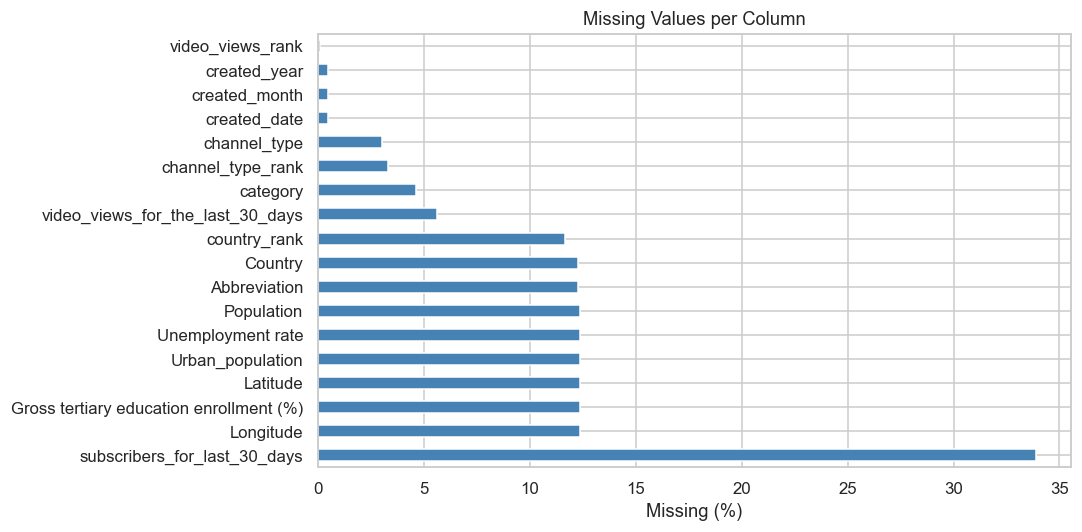

In [6]:
missing = df_rd.isnull().sum()
missing_pct = (missing / len(df_rd) * 100).round(2)
missing_df = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_df = missing_df[missing_df['missing_count'] > 0].sort_values('missing_pct', ascending=False)
print(missing_df)

#Visualise
fig, ax = plt.subplots(figsize=(10, 5))
missing_df['missing_pct'].plot(kind='barh', ax=ax, color='steelblue')
ax.set_xlabel('Missing (%)')
ax.set_title('Missing Values per Column')
plt.tight_layout()
plt.show()

What the above cell does:
In the cell above we have performed missing value correction wherein the number and percentage of missing values for every column is calculated, and post that filtered to only show columns that have at least one missing value, and then sorted them by missing percentage in descending order and visualised the result as a horizontal bar chart.
Result: 
According to the percentage calculated the feild having maximumum missing value is the "subscribers_for_last_30_days" with 34% closely followed by other feilds with 12% missing values like "longitude, Latitude" and "Population" etc.

    3.3 Drop Rows Missing Key Feilds

According to the dataset the important feilds for dashboard are subscribers, vedio_views, and category and rows missing any of these data are not usefull, hence those rows are dropped. So we are able to record exactly how many records are lost at each step.

In [7]:
df = df_rd.copy()
print(f'Records before cleaning: {len(df)}')

#Drop rows missing core numeric feilds
key_feilds = ['subscribers', 'video views', 'uploads']
before = len(df)
df = df.dropna(subset=key_feilds)
after = len(df)
print(f'Dropped {before - after} row missing category. Remaining: {after}')
print(f'\nTotal records removed: {len(df_rd) - after} ({(len(df_rd)-after)/len(df_rd)*100:.1f}% of raw data)')

Records before cleaning: 995
Dropped 0 row missing category. Remaining: 995

Total records removed: 0 (0.0% of raw data)


What the above cell does:
In the cell above df_copy creates a working copy of raw data frame and then removes rows that are missing values in core analysis columns like subscribers, video_views and uploads.

Result:
As a result the record count is printed before and after each drop operation so that impact can be traced records before and remaining is 995 and as per data and key feilds selected 0 rows were dropped.


    3.4 Column Renaming and Type Corecion

In [8]:
# Standardising column names to snake_case 
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(' ','_')
    .str.replace(r'[^\w]', '_', regex=True)
)

print('Renamed columns:', df.columns.tolist())    

Renamed columns: ['rank', 'youtuber', 'subscribers', 'video_views', 'category', 'title', 'uploads', 'country', 'abbreviation', 'channel_type', 'video_views_rank', 'country_rank', 'channel_type_rank', 'video_views_for_the_last_30_days', 'lowest_monthly_earnings', 'highest_monthly_earnings', 'lowest_yearly_earnings', 'highest_yearly_earnings', 'subscribers_for_last_30_days', 'created_year', 'created_month', 'created_date', 'gross_tertiary_education_enrollment____', 'population', 'unemployment_rate', 'urban_population', 'latitude', 'longitude']


What the above cell does:
In the above cell the str.strip function removes leading and trailing whitespaces that would survive the other transformations and create invisible naming incosistencies. Then with lower() function normalise the case before proceeding and then removing the spaces before regex for clarity and the catching and replacing any remaining special characters that were not spaces.

Result:
Gives the list of renamed columns after the functions are performed and columns are renamed: 'rank', 'youtuber', 'subscribers', 'video_views', 'category', 'title', 'uploads', 'country', 'abbreviation', 'channel_type', 'video_views_rank', 'country_rank', 'channel_type_rank', 'video_views_for_the_last_30_days', 'lowest_monthly_earnings', 'highest_monthly_earnings', 'lowest_yearly_earnings', 'highest_yearly_earnings', 'subscribers_for_last_30_days', 'created_year', 'created_month', 'created_date', 'gross_tertiary_education_enrollment____', 'population', 'unemployment_rate', 'urban_population', 'latitude', 'longitude'

In [9]:
# Coerce numeric columns - some may be read as object due to commas or symbols
num_cols = ['subscribers', 'vedio_views', 'uploads', 'vedio_views_rank', 'country_rank', 'channels_type_rank', 'video_views_for_the_last_30_days', 'lowest_monthly_earnings', 'highest_yearly_earnings', 'subscribers_for_last_30_days', 'created_year', 'gross_teritary_education_enrollment____', 'population', 'unemployment_rate', 'urban_population', 'latitude', 'longitude']

for col in num_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

print('Numeric coercion complete.')

Numeric coercion complete.


What the above cell does:
The above cell iteration over a list of columns that should be numeric and applies pd.to_numeric() to each, forcing any non-convertible values to NaN rather than rising an error.

    3.5 Category standardisation

In [10]:
#Standardise category labels to Title Case
df['category'] = df['category'].astype(str).str.strip().str.title()

#Standardise channel_type to Title Case
if 'channel_type' in df.columns:
    df['channel_type'] = df['channel_type'].astype(str).str.strip().str.title()

print('Category value counts:')
print(df['category'].value_counts())

Category value counts:
category
Entertainment            241
Music                    202
People & Blogs           132
Gaming                    94
Comedy                    69
Film & Animation          46
Nan                       46
Education                 45
Howto & Style             40
News & Politics           26
Science & Technology      17
Shows                     13
Sports                    11
Pets & Animals             4
Trailers                   2
Nonprofits & Activism      2
Movies                     2
Autos & Vehicles           2
Travel & Events            1
Name: count, dtype: int64


What the above cell does:
The above cell converts the category and channel_type columns to Title Case and strips any surrounding whitespaces.

    3.6 Derived features

In [11]:
#Average monthly earnings midpoints
if 'lowest_monthly_earnings' in df.columns and 'highest_monthly_earnings' in df.columns:
    df['avg_monthly_earnings'] = (df['lowest_monthly_earnings'] + df['highest_monthly_earnings']) / 2

#Average yearly earnings midpoint
if 'lowest_yearly_earnings' in df.columns and 'highest_yearly_earnings' in df.columns:
    df['avg_yearly_earnings'] = (df['lowest_yearly_earnings'] + df['highest_yearly_earnings']) / 2

#Views per subscriber ratio (engagement proxy)
df['views_per_subscriber'] = df['video_views'] / df['subscribers'].replace(0, np.nan)

#Channel age (years since creation)
if 'created_year' in df.columns:
    df['channel_age_years'] = 2023 - df['created_year']

print('Derived columns added.')
df[['avg_monthly_earnings', 'avg_yearly_earnings', 'views_per_subscriber', 'channel_age_years']].describe()
    

Derived columns added.


,avg_monthly_earnings,avg_yearly_earnings,views_per_subscriber,channel_age_years
count,9.950000e+02,9.950000e+02,995.000000,990.000000
mean,3.133470e+05,3.762036e+06,458.258976,10.369697
std,6.102391e+05,7.329103e+06,283.059314,4.512503
min,0.000000e+00,0.000000e+00,0.000000,1.000000
25%,2.310000e+04,2.772000e+05,246.172887,7.000000
50%,1.130000e+05,1.379750e+06,422.074109,10.000000
75%,3.223500e+05,3.877550e+06,612.872811,14.000000
max,7.225450e+06,8.680000e+07,2328.053424,53.000000


What the above cell does:
The code above is used to generate new derived variables, from existing columns in the dataset, for further analysis.
1. Average Monthly Earnings: Estimates the average middle monthly income.
2. Average Yearly Earnings: Calculates the average of annual earnings projections for better comparison and analysis.
3. The average number of views per subscriber.Average number of views per subscriber.  
4. Engagement Metrics: number of views per subscriber, a basic engagement measurement. To prevent division errors, values of zero are replaced with the value `NaN`.
5. Channel Age: Determines each channel's age by calculating the year that it was formed minus the year 2023.
6. The features are summarized using `.describe()`, which returns mean, min, max, quartiles etc.Finally summary statistics (mean, minimum, maximum, quartiles etc.) of newly created features are returned using `.describe()`.

    3.7 Checking the outliers

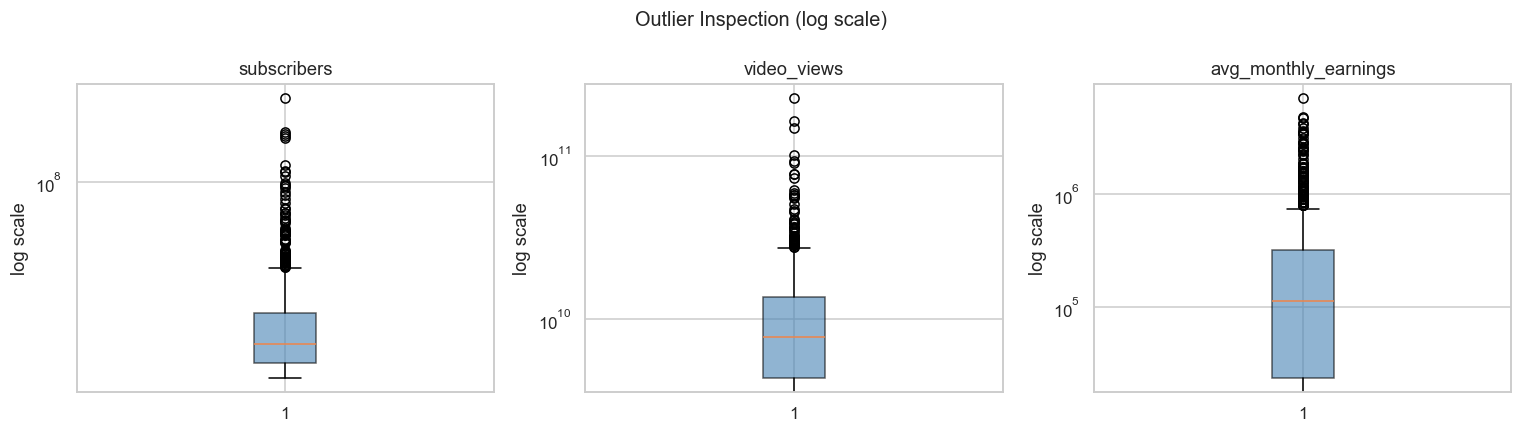


Top 5 by subscribers:
                     youtuber  subscribers          category        country
0                    T-Series    245000000             Music          India
1              YouTube Movies    170000000  Film & Animation  United States
2                     MrBeast    166000000     Entertainment  United States
3  Cocomelon - Nursery Rhymes    162000000         Education  United States
4                   SET India    159000000             Shows          India


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, ['subscribers', 'video_views', 'avg_monthly_earnings']):
    if col in df.columns:
        ax.boxplot(df[col].dropna(), vert=True, patch_artist=True, boxprops=dict(facecolor='steelblue', alpha=0.6))
        ax.set_title(col)
        ax.set_yscale('log')
        ax.set_ylabel('log scale')

plt.suptitle('Outlier Inspection (log scale)', fontsize=13)
plt.tight_layout()
plt.show()

print('\nTop 5 by subscribers:')
print(df.nlargest(5, 'subscribers')[['youtuber', 'subscribers', 'category', 'country']])


Extereme values for feilds like subscribers and vedio_views are genuine (e.g., YouTube Movies and T-Series) are not removed as they represent the real world top creators and are meaningful data to be presented for the dashboard audience.

What the above cell does:

This code gives: potential outliers in the data set are displayed using boxplots for:
subscribers
video_views
avg_monthly_earnings
Each variable is plotted on a log scale to accentuate the large numbers and to clearly illustrate the distribution of data.
The boxplots are used to detect: Extreme high-value channels, skewed distributions and
variability within the data set.

Result:
Following the visual analysis, the code presents the top 5 YouTube channels by subscribers' numbers and their:
Channel name
Subscriber total
Category
Country

This will give you a quick look at the largest channels in the data set.

4. EXPLORARTORY DATA ANALYSIS

    4.1 Distribution of subscribers

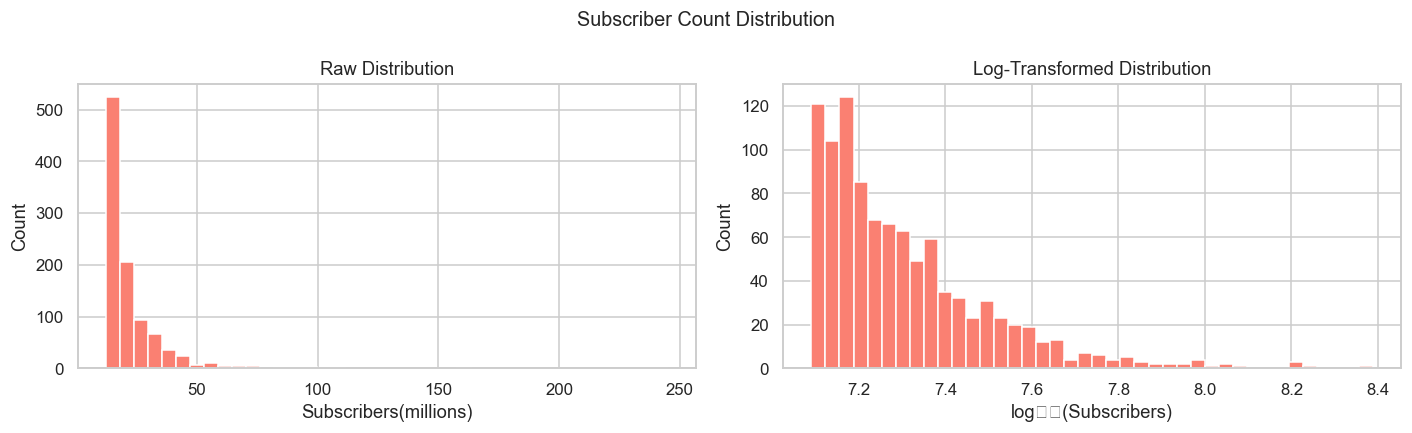

count    9.950000e+02
mean     2.298241e+07
std      1.752611e+07
min      1.230000e+07
25%      1.450000e+07
50%      1.770000e+07
75%      2.460000e+07
max      2.450000e+08
Name: subscribers, dtype: float64


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

#Raw
axes[0].hist(df['subscribers'] / 1e6, bins=40, color='salmon', edgecolor='white')
axes[0].set_xlabel('Subscribers(millions)')
axes[0].set_ylabel('Count')
axes[0].set_title('Raw Distribution')

#Log-transformation
axes[1].hist(np.log10(df['subscribers']), bins=40, color='salmon', edgecolor='white')
axes[1].set_xlabel('log₁₀(Subscribers)')
axes[1].set_ylabel('Count')
axes[1].set_title('Log-Transformed Distribution')

plt.suptitle('Subscriber Count Distribution', fontsize=13)
plt.tight_layout()
plt.show()

print(df['subscribers'].describe())

What the above cell does:
The code in the cell above plots two versions of the subscriber count distribution side by side: the raw values and the log-transformed values. The log-transformed is done for histogram which reveals the underlying shape of distribution more clearly as after log-transformation it often becomes approximately bell-shaped.

    4.2 Top Categories by channel count

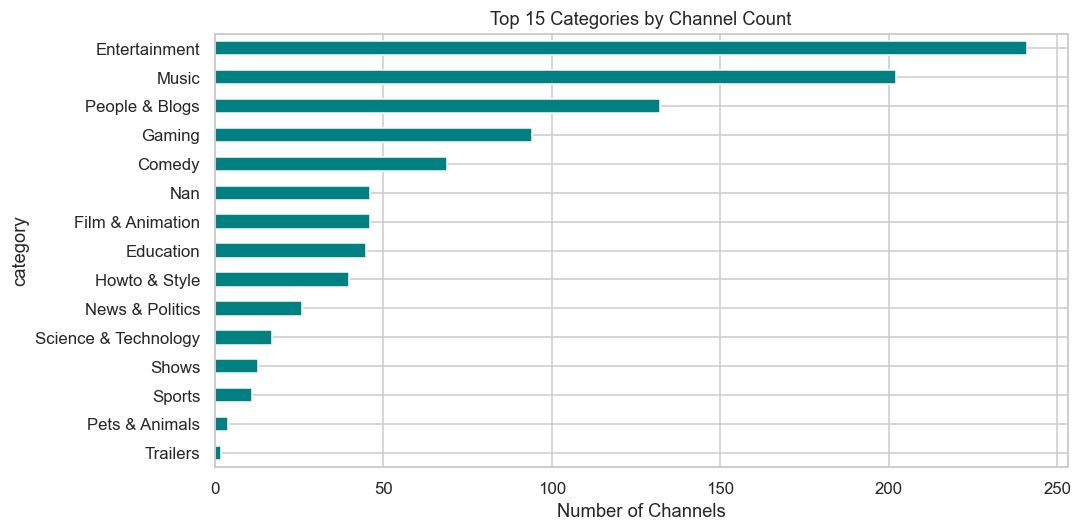

In [48]:
cat_counts = df['category'].value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 5))
cat_counts.sort_values().plot(kind='barh', ax=ax, color='teal', edgecolor='white')
ax.set_xlabel('Number of Channels')
ax.set_title('Top 15 Categories by Channel Count')
plt.tight_layout()
plt.show()

What the above cell does:
The cell counts the number of channels in each category, keeps the top 15, and plots them as a horizontal bar chart sorted by count ascending (so the longest bar chart is at the top). 

Result:
The dataset is mainly dominated by Entertainment, Music and People & Blogs channels in terms of Channel Count. This is indicative of the fact that YouTube was originally an entertainment site and the emergence of personal vlogging. Smaller categories like Nonprofits & Activism and Autos & Vehicles are poorly represented, and will impact the trustworthiness of the summary statistics for these categories in other charts. 

    4.3 Subscribers by Category(Box Plot)

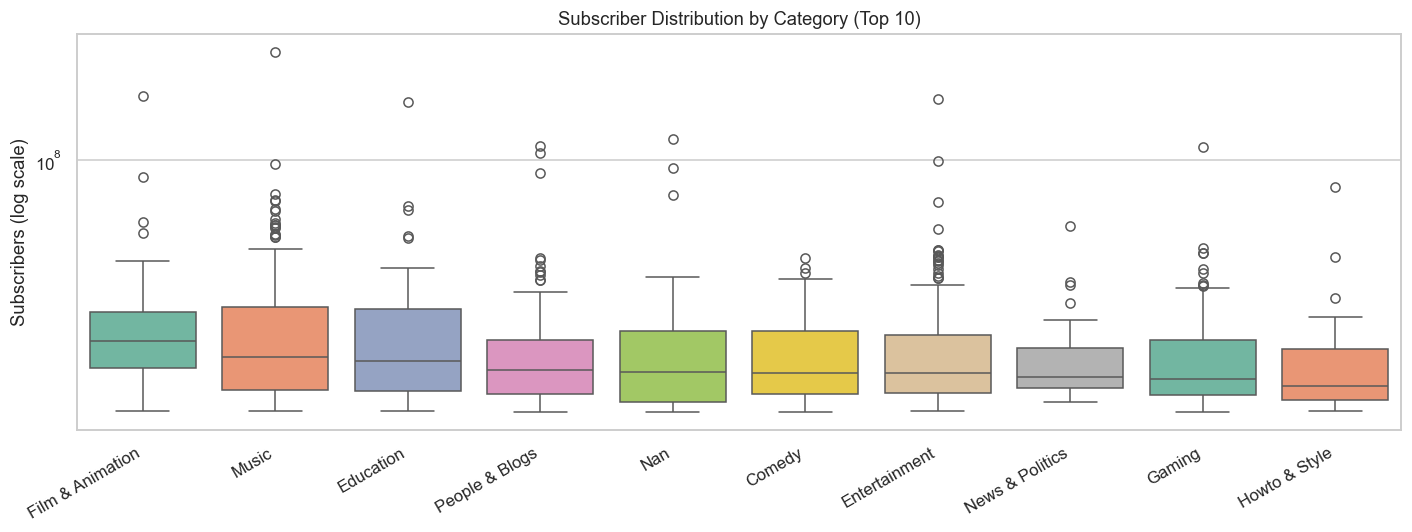

In [49]:
top_cats = df['category'].value_counts().head(10).index
df_top = df[df['category'].isin(top_cats)].copy()

order = df_top.groupby('category')['subscribers'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=df_top, x='category', y='subscribers', order=order, palette='Set2', ax=ax)
ax.set_yscale('log')
ax.set_ylabel('Subscribers (log scale)')
ax.set_xlabel('')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
ax.set_title('Subscriber Distribution by Category (Top 10)')
plt.tight_layout()
plt.show()

What the above cell does:
Filters the dataset to the top 10 categories, sorts them by the median number of subscribers (top-to-bottom) and creates a box plot of the filtered data with a log scaled y-axis.

Results:
The median subscribers for music channels are the highest followed by Entertainment channels. In some categories, such as Shows and Film & Animation, the interquartile ranges are fairly wide, suggesting a lot of variance: some channels are quite large (e.g. media franchises launched by established studios). The range of sizes within the categories, for example News & Politics, are more concentrated, indicating more uniformity in channel size within the category.


    4.4 Channels created over time

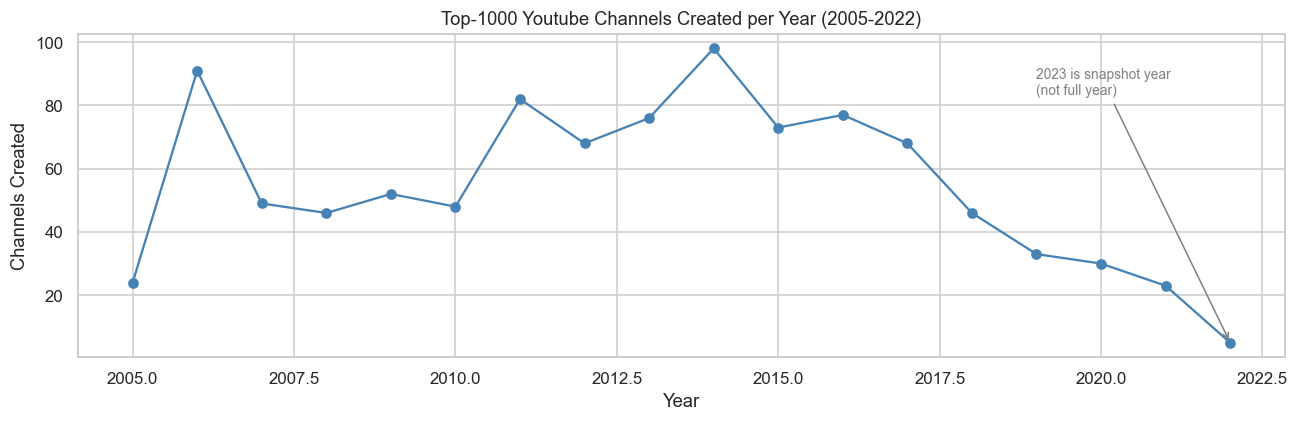

In [28]:
if 'created_year' in df.columns:
    year_count = df['created_year'].dropna().astype(int).value_counts().sort_index()
    year_count = year_count[(year_count.index >= 2005) & (year_count.index <= 2022)]  # Data only before 2023 included to take only complete data 

    fig, ax = plt.subplots(figsize=(12, 4))
    year_count.plot(kind='line', marker='o', ax=ax, color= 'steelblue')
    ax.set_xlabel('Year')
    ax.set_ylabel('Channels Created')
    ax.set_title('Top-1000 Youtube Channels Created per Year (2005-2022)') #Data before 2023 is included as 2023 was a snapshot year and was not a full year of creation data 
    ax.annotate('2023 is snapshot year\n(not full year)', xy=(2022, year_count.get(2022, 0)), xytext=(2019, year_count.max()*0.85), arrowprops=dict(arrowstyle='->', color='grey'), fontsize=9, color='grey')
    plt.tight_layout()
    plt.show()

What the above cell does:
Plots a line graph with marks to show the number of best channels (2005-2022) that have been created. A note is added to make it clear that 2023 is not included.

Results:
The creation of channels in the top tier reaches a high in the mid-2010s. This is probably due to the evolution of the YouTube Partner Programme (2007/2012), and the generalisation of broadband video viewing. The trend after the peak is not a decrease in the number of YouTube channels created, but because the number of large channels that are already in existence continues to grow, it is becoming more difficult to get into the top tier.

    4.5 Country Distribution for Top 15 countries:

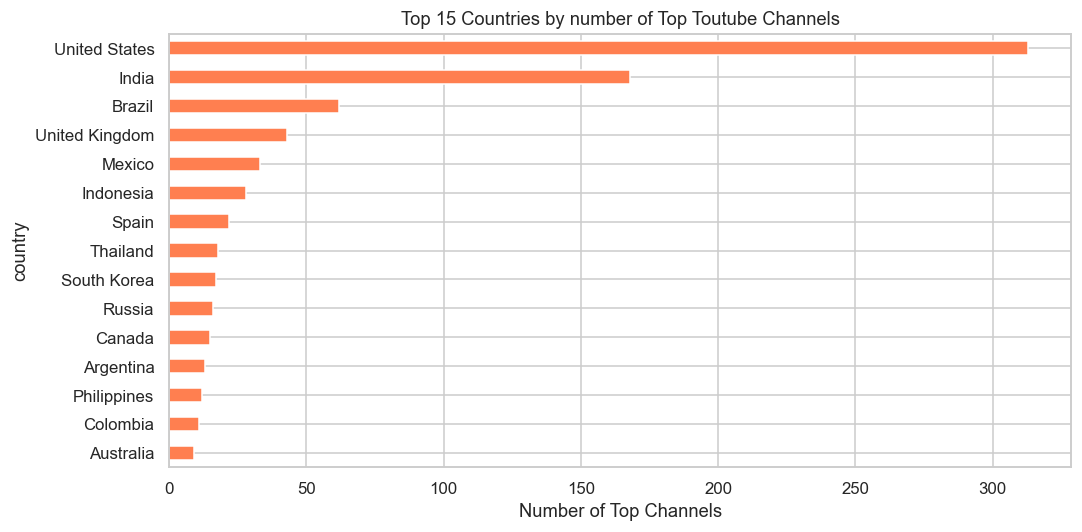

In [50]:
if 'country' in df.columns:
    country_counts = df['country'].value_counts().head(15)
    fig, ax = plt.subplots(figsize=(10, 5))
    country_counts.sort_values().plot(kind='barh', ax=ax, color='coral', edgecolor='white')
    ax.set_xlabel('Number of Top Channels')
    ax.set_title('Top 15 Countries by number of Top Toutube Channels')
    plt.tight_layout()
    plt.show()

What the above cell does:
Counts the number of super channels per country, selects the 15 most frequented countries and displays the number of super channels as a horizontal bar chart.

Results:
The number of best-of-breed channels is much more than in the USA, followed by India. This is due to the size of content markets in both English and Hindi, as well as the fact that the US is the country of origin for YouTube's English-language content, providing an early-mover advantage to those making English-language content. The high Indian presence is indicative of the internet penetration and size of the Hindi speaking content market.

    4.6 Correlation Heatmap 

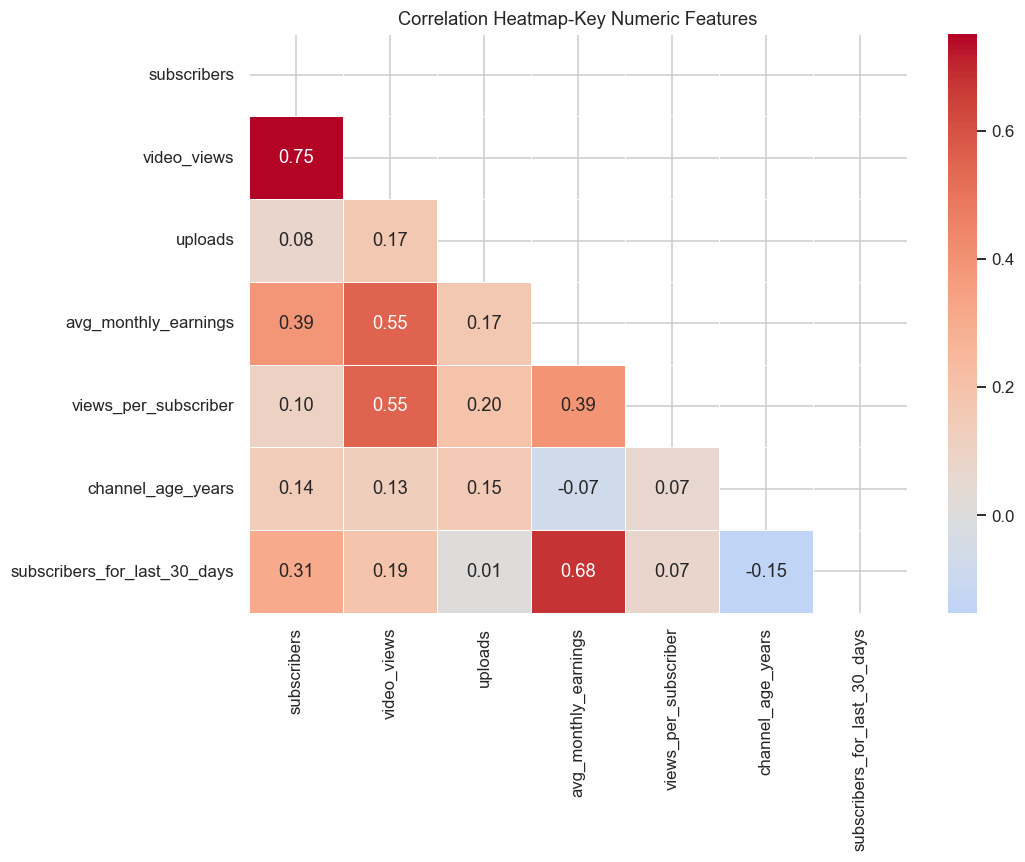

In [51]:
corr_cols=['subscribers', 'video_views', 'uploads', 'avg_monthly_earnings', 'views_per_subscriber', 'channel_age_years', 'subscribers_for_last_30_days', 'vedio_views_for_the_last_30_days']
corr_cols=[c for c in corr_cols if c in df.columns]
corr_matrix=df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask=np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax, linewidth=0.5)
ax.set_title('Correlation Heatmap-Key Numeric Features')
plt.tight_layout()
plt.show()


What the above cell does:
Calculates all the Pearson correlation between the key numeric columns and presents the lower triangle of the correlation matrix as a heatmap with colours.

Results:
As you might expect, the two are highly correlated—9. on one hand, and video_views on the other, with r > 0.8. avg_monthly_earnings is even more highly correlated with the two, indicating that monetisation is more likely to be driven by audience scale. The 30 days metrics (subscribers_for_last_30_days, video_views_for_the_last_30_days) are reasonably correlated with the total numbers, meaning that the current trend is partially related to the historical size. Notably, views_per_subscriber has weak correlation with raw subscribers, which suggests that there aren't any obvious patterns in engagement efficiency across all channel sizes — smaller isn't necessarily more or less engaged than bigger.


    4.7 Earning vs Subscriber Scatter plot graph (log-log)

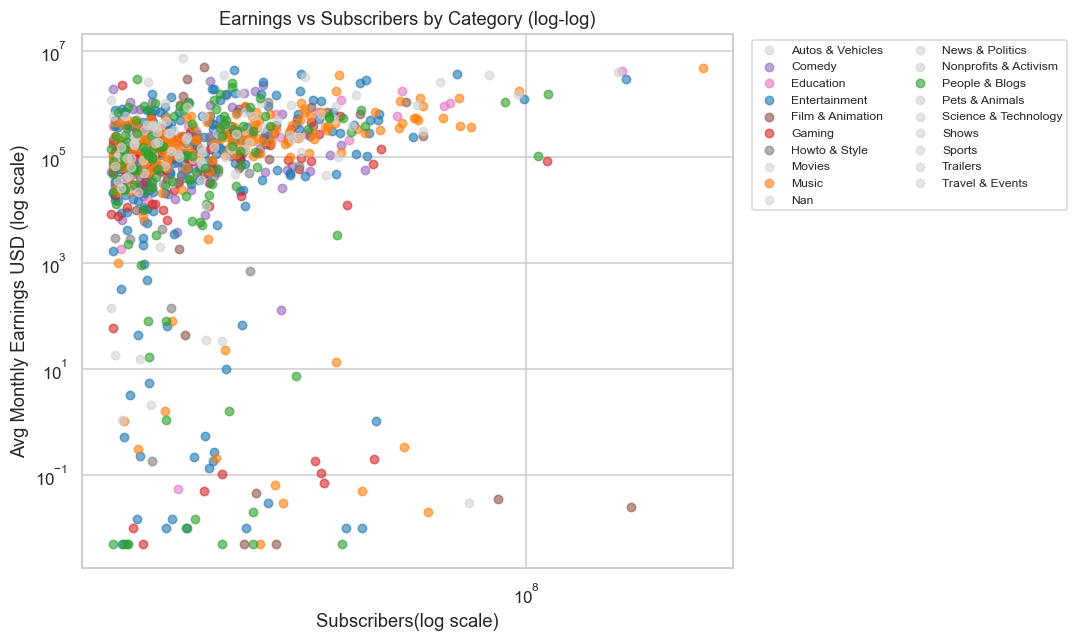

In [52]:
if 'avg_monthly_earnings' in df.columns:
    plot_df = df.dropna(subset = ['avg_monthly_earnings', 'subscribers'])
    plot_df = plot_df[plot_df['avg_monthly_earnings'] > 0]
    fig, ax = plt.subplots(figsize=(10, 6))
    top_cats_palette={c: sns.color_palette('tab10')[i]
                  for i, c in enumerate(plot_df['category'].value_counts().head(8).index)}
    for cat, group in plot_df.groupby('category'):
        color = top_cats_palette.get(cat, 'lightgrey')
        ax.scatter(group['subscribers'], group['avg_monthly_earnings'], alpha=0.6, s=30, label=cat, color=color)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Subscribers(log scale)')
    ax.set_ylabel('Avg Monthly Earnings USD (log scale)')
    ax.set_title('Earnings vs Subscribers by Category (log-log)')
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8, ncol=2)
    plt.tight_layout()
    plt.show()

What the above cell does:
Graphs each channel as a point on a scatter plot with the number of subscribers plotted along the x-axis and average monthly earnings plotted along the y-axis (both axes are on a logarithmic scale) and colors the points according to the category.

Results:
The overall positive linear relationship on the log–log axes strongly suggests a power law relationship between subscribers and earnings for all categories (doubling the number of subscribers approximately doubles the earnings). The highest subscribers and highest earning channels are Music and Entertainment in the upper right quadrant. There is significant scatter around the trend line, however, suggesting that earnings are influenced by each of category, upload frequency and audience engagement independently of raw subscriber counts, which is why a multivariate analysis is also shown in the Streamlit dashboard.

5. EXPORTING THE CLEANED DATASET FOR DASHBOARD

In [40]:
df.to_csv('global-youtube_cleaned.csv', index=False)
print(f'Exported global-youtube_cleaned.csv - shape: {df.shape}')
print('\nFinal column list:')
print(df.columns.tolist())

Exported global-youtube_cleaned.csv - shape: (995, 32)

Final column list:
['rank', 'youtuber', 'subscribers', 'video_views', 'category', 'title', 'uploads', 'country', 'abbreviation', 'channel_type', 'video_views_rank', 'country_rank', 'channel_type_rank', 'video_views_for_the_last_30_days', 'lowest_monthly_earnings', 'highest_monthly_earnings', 'lowest_yearly_earnings', 'highest_yearly_earnings', 'subscribers_for_last_30_days', 'created_year', 'created_month', 'created_date', 'gross_tertiary_education_enrollment____', 'population', 'unemployment_rate', 'urban_population', 'latitude', 'longitude', 'avg_monthly_earnings', 'avg_yearly_earnings', 'views_per_subscriber', 'channel_age_years']
